# Single-epoch walkthrough: from raw data to the replay-content regressions

This notebook walks the **complete analysis pipeline for one session** —
`chimi`, day `20200213`, epoch `02_r1`, hippocampus (HPC) — from raw data
loading through every regression-model family.

**Why one epoch is the right unit.** The production pipeline
(`scripts/content/fit_replay_content_models.py`,
`scripts/content/compare_event_source_models.py`) fits **one model per session**,
where a *session* is a single `(animal, day, epoch)` tuple. Each conditional
model conditions on *event* or *stop* within that one session; the
population result is an aggregate of these per-session fits. So a
single-epoch fit here is not a toy — it is exactly one unit of the real
analysis. The population-level conclusions (and the caveats that several
single-session-suggestive effects only survive after autocorrelation /
multiple-comparison control) live one level up, across sessions.

**Decoding is loaded, not re-run.** The non-local state-space decoder is
GPU-heavy and runs for hours per epoch. Its outputs are already on disk
(`Processed-Data/*_results.nc`, `*_environment.pkl`,
`*_data_over_time.pkl`). We *show* the decode call for reference but **load**
its outputs, so this notebook runs end-to-end in well under a minute.

**Real functions only.** Every table and every model is built with the
project's own package functions (`continuum_swr_replay.analysis.replay.*`).
Nothing statistical is re-implemented inline — the notebook is a thin driver,
mirroring `scripts/prepare_replay_content_data.py:_process_session`.

## Pipeline

```
load_data ─► [decode: load precomputed] ─► data_over_time (dot)
   │                                              │
   │                          ┌───────────────────┼────────────────────┐
   │                          ▼                   ▼                    ▼
   │                   build_event_table   build_stop_table   (posterior .nc)
   │                          │                   │
   │                          ▼                   │
   │                 build_event_arm_table        │
   │                   /            \             │
   │                  ▼              ▼            │
   │       build_event_patch    add_arm_fixed     │
   │           _table            _effects         │
   └──────────────────┬──────────────┬────────────┘
                      ▼              ▼
        ┌─────────────┴───────┬──────┴────────┬─────────────────┐
        ▼                     ▼               ▼                 ▼
  M0–M7 arm content   P0–P4 patch    R0–R3 event rate   C_* next-arm choice
  (conditional        (conditional   (Poisson GLM,      (conditional logit,
   Poisson)            Poisson)       log-time offset)   stop × candidate arm)
```

In [1]:
import logging
import pickle

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

logging.basicConfig(level=logging.WARNING)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

# --- Data loading + decode outputs ---
from continuum_swr_replay.data_loaders import load_data
from continuum_swr_replay.parameters import PROCESSED_DATA_DIR
from continuum_swr_replay.analysis.replay.posterior_io import (
    load_conditional_posterior,
)

# --- Canonical table builders (same ones the prep script calls) ---
from continuum_swr_replay.analysis.replay.tables import (
    build_event_table,
    build_event_arm_table,
    build_event_patch_table,
    build_stop_table,
)
from continuum_swr_replay.analysis.replay._helpers import add_arm_fixed_effects

# --- Model specifications (the four families) ---
from continuum_swr_replay.analysis.replay.model_specs import (
    MODEL_HIERARCHY,  # M0–M7  : arm content
    MODEL_PATCH,      # P0–P4  : patch content
    MODEL_RATE,       # R0–R3  : event rate per stop
    MODEL_CHOICE,     # C_*    : next-arm choice
)

# --- Fitters (statsmodels conditional models / Poisson GLM) ---
from continuum_swr_replay.analysis.replay.fitting import fit_conditional_poisson
from continuum_swr_replay.analysis.replay.rate_model import fit_rate_model
from continuum_swr_replay.analysis.replay.choice_prediction import (
    build_choice_dataset,
    fit_choice_model,
)

/cumulus/edeno/continuum-swr-replay/.venv/lib/python3.11/site-packages/datajoint/plugin.py:4: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources
[2026-06-17 12:30:22,491][INFO]: DataJoint 0.14.6 connected to edeno@lmf-db.cin.ucsf.edu:3306
INFO:datajoint:DataJoint 0.14.6 connected to edeno@lmf-db.cin.ucsf.edu:3306


## 0. Session selection

`chimi20200213_02_r1` — confirmed to have precomputed decoder outputs and a
rich event count. The identifiers below drive every subsequent cell; point
them at another `(nwb_file_name, epoch_name)` to repeat the whole notebook
for a different epoch of the same day (`04_r2`, `06_r3`) or any other
session.

In [2]:
NWB_FILE_NAME = "chimi20200213_.nwb"
EPOCH_NAME = "02_r1"
BRAIN_AREA = "HPC"

SESSION_ID = f"{NWB_FILE_NAME.replace('_.nwb', '')}_{EPOCH_NAME}_{BRAIN_AREA}"
DOT_FILE = PROCESSED_DATA_DIR / f"{SESSION_ID}_80_data_over_time.pkl"
ENV_FILE = PROCESSED_DATA_DIR / f"{SESSION_ID}_environment.pkl"
RESULTS_FILE = PROCESSED_DATA_DIR / f"{SESSION_ID}_results.nc"

for p in (DOT_FILE, ENV_FILE, RESULTS_FILE):
    print(f"{'OK ' if p.exists() else 'MISSING'} {p.name}")

OK  chimi20200213_02_r1_HPC_80_data_over_time.pkl
OK  chimi20200213_02_r1_HPC_environment.pkl
OK  chimi20200213_02_r1_HPC_results.nc


## 1. Load raw session data

`load_data()` orchestrates the whole loader: DLC position linearized onto the
track graph, spike times per brain area, ripple-band LFP and detected
ripples, DIO task events, trials, and derived task variables. It queries
Spyglass, so this is the slowest cell (~30–60 s).

In [3]:
data = load_data(NWB_FILE_NAME, EPOCH_NAME, ripple_detector_name="Kay")

position_info = data["position_info"]
trials = data["trials"]
track_graph = data["track_graph"]
ripple_times = data["ripple_times"]

print("spike_times brain areas:", list(data["spike_times"].keys()))
print("position_info :", position_info.shape, "| time-indexed in seconds")
print("trials        :", trials.shape)
print("ripple_times  :", ripple_times.shape)
print("\nposition_info columns:\n", list(position_info.columns))

/cumulus/edeno/continuum-swr-replay/.venv/lib/python3.11/site-packages/numpy/_core/numeric.py:476: RuntimeWarning: invalid value encountered in cast
  multiarray.copyto(res, fill_value, casting='unsafe')
[2026-06-17 12:35:29,651][WARNING]: Skipped checksum for file with hash: d35d597a-c048-d50d-4027-9240721ee8ac, and path: /stelmo/nwb/raw/chimi20200213_.nwb
[2026-06-17 12:35:29,658][WARNING]: Skipped checksum for file with hash: d35d597a-c048-d50d-4027-9240721ee8ac, and path: /stelmo/nwb/raw/chimi20200213_.nwb
[2026-06-17 12:35:29,664][WARNING]: Skipped checksum for file with hash: d35d597a-c048-d50d-4027-9240721ee8ac, and path: /stelmo/nwb/raw/chimi20200213_.nwb
[2026-06-17 12:35:29,669][WARNING]: Skipped checksum for file with hash: d35d597a-c048-d50d-4027-9240721ee8ac, and path: /stelmo/nwb/raw/chimi20200213_.nwb
[2026-06-17 12:35:29,674][WARNING]: Skipped checksum for file with hash: d35d597a-c048-d50d-4027-9240721ee8ac, and path: /stelmo/nwb/raw/chimi20200213_.nwb
[2026-06-17 12:3

spike_times brain areas: ['HPC']
position_info : (1807725, 11) | time-indexed in seconds
trials        : (279, 10)
ripple_times  : (778, 2)

position_info columns:
 ['head_position_x', 'head_position_y', 'head_orientation', 'head_velocity_x', 'head_velocity_y', 'head_speed', 'linear_position', 'track_segment_id', 'projected_x_position', 'projected_y_position', 'patch_id']


In [4]:
trials.head()

,is_reward,start_time,end_time,is_patch_change,from_well,to_well,from_patch,to_patch,duration,goal_arrival_time
trial_number,,,,,,,,,,
1,True,1.581636e+09,1.581636e+09,False,3,2,2,2,36.288432,1.581636e+09
2,True,1.581636e+09,1.581636e+09,True,2,0,2,1,26.921571,1.581636e+09
3,False,1.581636e+09,1.581636e+09,False,0,1,1,1,14.855222,1.581636e+09
4,True,1.581636e+09,1.581636e+09,False,1,0,1,1,13.975665,1.581636e+09
5,True,1.581636e+09,1.581636e+09,True,0,5,1,3,15.334975,1.581636e+09


### 1a. Orientation plots

Linearized position over the whole epoch (left) and the 2-D track-graph
layout with the nine arms the decoder maps replay onto (right). The
"three-legged spider": six leaf arms (well ↔ patch junction, arms 0–5) and
three trunk arms (patch junction ↔ center, arms 6–8).

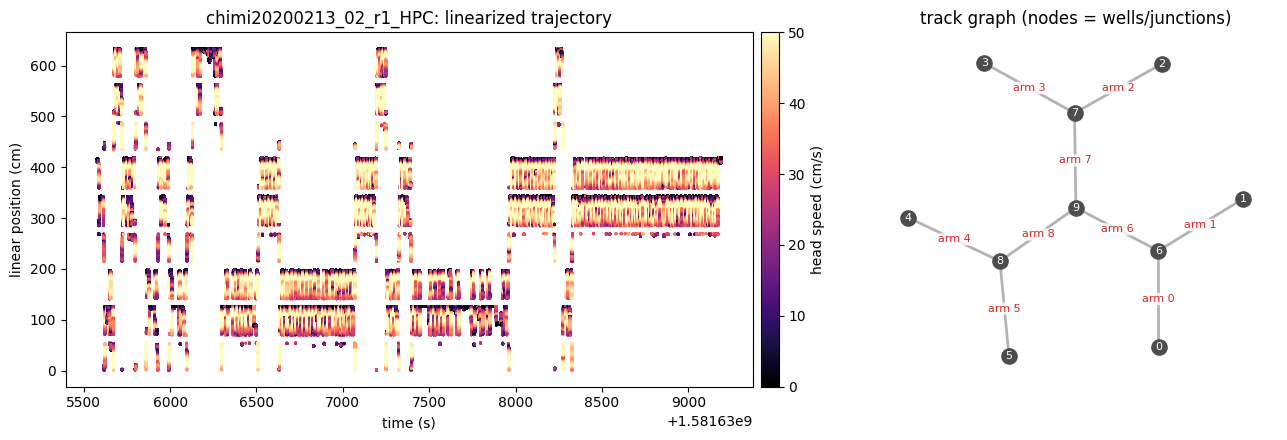

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), width_ratios=[2, 1])

# Linearized position over time, colored by head speed.
ax = axes[0]
sc = ax.scatter(
    position_info.index,
    position_info["linear_position"],
    c=position_info["head_speed"],
    s=1,
    cmap="magma",
    vmin=0,
    vmax=50,
    rasterized=True,
)
ax.set(xlabel="time (s)", ylabel="linear position (cm)",
       title=f"{SESSION_ID}: linearized trajectory")
fig.colorbar(sc, ax=ax, label="head speed (cm/s)", pad=0.01)

# 2-D track graph with arm (edge) ids.
ax = axes[1]
import networkx as nx

node_pos = {n: track_graph.nodes[n]["pos"] for n in track_graph.nodes}
nx.draw_networkx_edges(track_graph, node_pos, ax=ax, edge_color="0.7", width=2)
nx.draw_networkx_nodes(track_graph, node_pos, ax=ax, node_size=120,
                       node_color="0.3")
nx.draw_networkx_labels(track_graph, node_pos, ax=ax, font_color="white",
                        font_size=8)
for u, v, d in track_graph.edges(data=True):
    if "edge_id" in d:
        mx = 0.5 * (node_pos[u][0] + node_pos[v][0])
        my = 0.5 * (node_pos[u][1] + node_pos[v][1])
        ax.text(mx, my, f"arm {d['edge_id']}", color="C3", fontsize=8,
                ha="center", va="center",
                bbox=dict(boxstyle="round,pad=0.1", fc="white", ec="none",
                          alpha=0.8))
ax.set(title="track graph (nodes = wells/junctions)")
ax.set_aspect("equal")
ax.axis("off")
fig.tight_layout()

## 2. Decoding — load precomputed outputs

The non-local clusterless detector (`NonLocalClusterlessDetector`) was fit on
no-ripple training timepoints and applied to the whole epoch by
`scripts/decoding/run_decoding_bandit.py`. For reference, that call is:

```python
# NOT executed here — GPU, hours. Outputs already on disk.
from scripts.run_decoding_bandit import run_decode
run_decode(nwb_file_name=NWB_FILE_NAME, epoch_name=EPOCH_NAME,
           brain_area="HPC")
```

We load its three artifacts:

* **`data_over_time` (`dot`)** — the per-timebin summary table: state
  probabilities, MAP decode (`map_estimate`), event labels
  (`non_local_event`, `SWR_event`), head speed, etc. This is the master input
  to every downstream table builder.
* **`environment`** — the place-bin / track-graph environment used to map a
  decoded position to an arm.
* **conditional posterior** (`results.nc`) — the full `(time, position)`
  probability distribution conditioned on the non-local state, used both for
  visualization here and for the posterior-weighted table columns.

In [6]:
dot = pd.read_pickle(DOT_FILE)
with open(ENV_FILE, "rb") as f:
    env = pickle.load(f)
posterior = load_conditional_posterior(RESULTS_FILE)

n_nonlocal_events = int(dot.loc[dot["non_local_event"] > 0, "non_local_event"].nunique())
print("dot           :", dot.shape)
print("posterior     :", dict(posterior.sizes))
print("n place bins  :", env.place_bin_centers_.shape[0])
print("n_nonlocal_events (raw labels):", n_nonlocal_events)
print("\ndot state/event columns:\n",
      [c for c in dot.columns if "prob" in c or "event" in c or c == "map_estimate"])

dot           : (1807732, 42)
posterior     : {'time': 1807732, 'position': 270}
n place bins  : 270
n_nonlocal_events (raw labels): 1714

dot state/event columns:
 ['non_local_event', 'SWR_event', 'MUA_event', 'Local_prob', 'No-Spike_prob', 'Non-Local_Continuous_prob', 'Non-Local_Fragmented_prob', 'map_estimate']


### 2a. One decoded non-local event

Pick the highest-probability non-local event and show the conditional
posterior over linear position through its window, with the animal's actual
(stationary) position overlaid. A non-local event is a stretch where the
decoded position departs from where the animal physically is — the
"replay-like" content this whole pipeline quantifies.

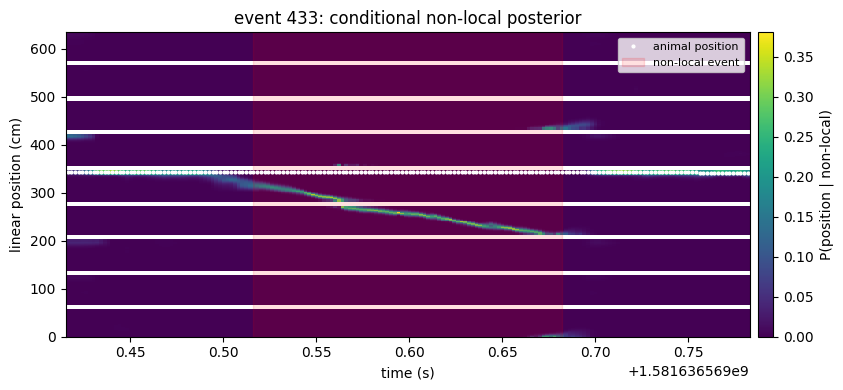

In [7]:
nonlocal_summed = (
    dot["Non-Local_Continuous_prob"] + dot["Non-Local_Fragmented_prob"]
)
labels = dot.loc[dot["non_local_event"] > 0, "non_local_event"]
# peak non-local prob per event label -> choose the strongest event
peak_per_event = nonlocal_summed.groupby(dot["non_local_event"]).max()
peak_per_event = peak_per_event[peak_per_event.index > 0]
example_label = peak_per_event.idxmax()

ev_mask = dot["non_local_event"] == example_label
ev_times = dot.index[ev_mask]
pad = 0.10  # seconds of context on each side
t0, t1 = ev_times.min() - pad, ev_times.max() + pad

post_win = posterior.sel(time=slice(t0, t1)).load()
pos_win = dot.loc[t0:t1, "linear_position"]

fig, ax = plt.subplots(figsize=(9, 4))
mesh = ax.pcolormesh(
    post_win["time"].values,
    post_win["position"].values,
    post_win.values.T,
    cmap="viridis",
    shading="auto",
    rasterized=True,
)
ax.plot(pos_win.index, pos_win.values, ".", color="white", ms=4,
        label="animal position")
ax.axvspan(ev_times.min(), ev_times.max(), color="red", alpha=0.12,
           label="non-local event")
ax.set(xlabel="time (s)", ylabel="linear position (cm)",
       title=f"event {int(example_label)}: conditional non-local posterior")
ax.legend(loc="upper right", fontsize=8)
fig.colorbar(mesh, ax=ax, label="P(position | non-local)", pad=0.01)
fig.tight_layout()

## 3. Event classification table

`build_event_table` produces **one row per non-local event**. It wraps the
canonical `build_classified_nonlocal_event_table` (full-window timing,
per-event speed summary, peak non-local probability, the 3-way SWR
`overlap_class` and matched SWR) and adds the replay-content filtered-window
columns. The conditional `posterior` is passed so posterior-weighted columns
are populated.

In [8]:
event_table = build_event_table(
    dot, env, trials, track_graph, conditional_posterior=posterior
)
print("event_table:", event_table.shape)
print("\noverlap_class counts:\n", event_table["overlap_class"].value_counts())
event_table[
    [
        "event_id", "event_start", "event_end", "event_duration",
        "mean_speed", "peak_nonlocal_prob", "overlap_class", "is_swr",
    ]
].head()

event_table: (1714, 55)

overlap_class counts:
 overlap_class
non_swr          948
swr_contained    457
swr_partial      309
Name: count, dtype: int64


,event_id,event_start,event_end,event_duration,mean_speed,peak_nonlocal_prob,overlap_class,is_swr
0,4684575748763187657,1.581636e+09,1.581636e+09,0.028,0.710441,0.991874,non_swr,False
1,507077526136763520,1.581636e+09,1.581636e+09,0.064,0.504014,0.999833,non_swr,False
2,1227836852711955074,1.581636e+09,1.581636e+09,0.042,0.370488,1.000061,non_swr,False
3,7289660146915800854,1.581636e+09,1.581636e+09,0.034,0.910535,0.907365,non_swr,False
4,6602360879545841726,1.581636e+09,1.581636e+09,0.026,1.020461,1.000046,non_swr,False


### 3a. Event summary for this epoch

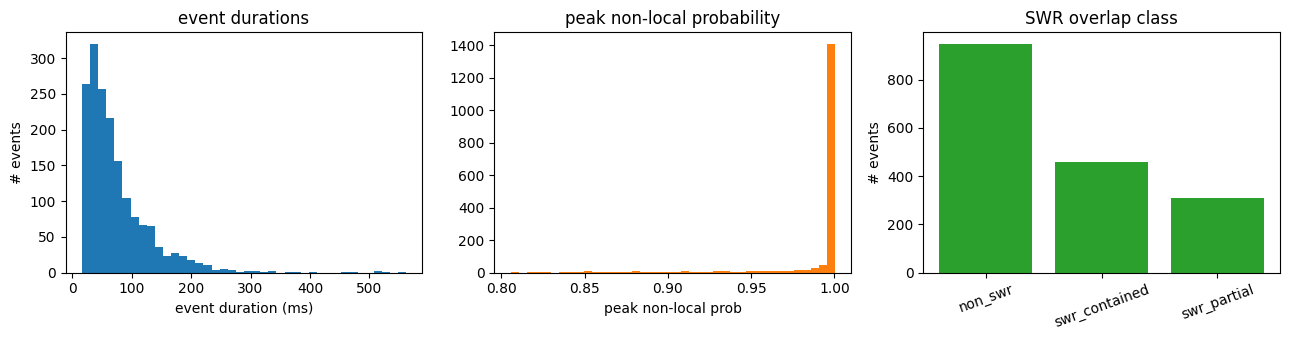

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

axes[0].hist(event_table["event_duration"] * 1e3, bins=40, color="C0")
axes[0].set(xlabel="event duration (ms)", ylabel="# events",
            title="event durations")

axes[1].hist(event_table["peak_nonlocal_prob"], bins=40, color="C1")
axes[1].set(xlabel="peak non-local prob", title="peak non-local probability")

vc = event_table["overlap_class"].value_counts()
axes[2].bar(vc.index.astype(str), vc.values, color="C2")
axes[2].set(ylabel="# events", title="SWR overlap class")
axes[2].tick_params(axis="x", rotation=20)
fig.tight_layout()

## 4. Stop table

`build_stop_table` produces **one row per stopping period** (immobility
bout), *including zero-event stops*. This is the denominator the event-rate
model needs and the unit the choice model is built on. It is a function of
immobility bouts, not of non-local events, so it is built directly from
`dot` + `trials` + `track_graph`.

In [10]:
stop_table = build_stop_table(dot, trials, track_graph)
print("stop_table:", stop_table.shape)
print("stops with >=1 event:", int((stop_table["n_events"] > 0).sum()),
      "/", len(stop_table))
stop_table.head()

stop_table: (2239, 26)
stops with >=1 event: 485 / 2239


,animal,day,epoch,stop_idx,stop_id,stop_start,stop_end,immobility_time,recent_trial_reward_rate,is_swr_stop,is_mua_stop,has_replay,n_events,is_after_switch,is_after_omission,is_after_reward,is_after_stay,reward_outcome,is_stay,current_arm,prev_arm,next_arm,last_rewarded_arm,current_patch,prev_patch,next_patch
0,chimi,20200213,02_r1,0,8393993873049741010,1.581636e+09,1.581636e+09,1.923999,NaN,False,False,True,4,0.0,0.0,1.0,1.0,1.0,0.0,3.0,3.0,0.0,NaN,2.0,2.0,1.0
1,chimi,20200213,02_r1,1,4684575748763187657,1.581636e+09,1.581636e+09,3.577998,NaN,True,True,True,4,0.0,0.0,1.0,1.0,1.0,0.0,3.0,3.0,0.0,NaN,2.0,2.0,1.0
2,chimi,20200213,02_r1,2,507077526136763520,1.581636e+09,1.581636e+09,1.227999,NaN,False,False,True,5,0.0,0.0,1.0,1.0,1.0,0.0,3.0,3.0,0.0,NaN,2.0,2.0,1.0
3,chimi,20200213,02_r1,3,1227836852711955074,1.581636e+09,1.581636e+09,0.696000,NaN,False,False,True,2,0.0,0.0,1.0,1.0,1.0,0.0,3.0,3.0,0.0,NaN,2.0,2.0,1.0
4,chimi,20200213,02_r1,4,7289660146915800854,1.581636e+09,1.581636e+09,0.104000,NaN,False,False,False,0,0.0,0.0,1.0,1.0,1.0,0.0,3.0,3.0,0.0,NaN,2.0,2.0,1.0


## 5. Long-format design matrices (arm and patch)

`build_event_arm_table` expands the event table to **one row per
(event, arm)** — nine arms per event — and computes the full per-event
predictor set used by M0–M7:

* `arm_count_hard` — response: # MAP timebins this event spent on this arm
* `is_current`, `is_prev`, `is_last_rewarded_elsewhere` — spatial context
* `recent_reward_rate`, `visit_recency_demeaned` — value / memory
* `swr_x_*` — SWR-overlap interactions (M6/M7)

The only thing added on top is `add_arm_fixed_effects`, which writes the
`arm_fe_0…arm_fe_7` dummies (arm 8 is the reference) — the M0a geometry
baseline. `build_event_patch_table` collapses arms→patches (3 categories) for
the patch hierarchy.

In [11]:
event_arm_table = build_event_arm_table(
    event_table, dot, env, trials, track_graph, conditional_posterior=posterior
)
add_arm_fixed_effects(event_arm_table)  # in-place: adds arm_fe_0 … arm_fe_7

event_patch_table = build_event_patch_table(event_table, event_arm_table)

print("event_arm_table  :", event_arm_table.shape,
      f"({event_arm_table['event_id'].nunique()} events × 9 arms)")
print("event_patch_table:", event_patch_table.shape,
      f"({event_patch_table['event_id'].nunique()} events × 3 patches)")
print("\none event (9 arms):")
cols = ["event_id", "arm", "arm_count_hard", "is_current", "is_prev",
        "recent_reward_rate", "visit_recency_demeaned",
        "is_last_rewarded_elsewhere", "swr_x_current"]
event_arm_table.loc[
    event_arm_table["event_id"] == event_arm_table["event_id"].iloc[0], cols
]

event_arm_table  : (15426, 75) (1714 events × 9 arms)
event_patch_table: (5142, 17) (1714 events × 3 patches)

one event (9 arms):


,event_id,arm,arm_count_hard,is_current,is_prev,recent_reward_rate,visit_recency_demeaned,is_last_rewarded_elsewhere,swr_x_current
0,4684575748763187657,0,0,0,0,NaN,NaN,0,0
1,4684575748763187657,1,0,0,0,NaN,NaN,0,0
2,4684575748763187657,2,0,0,0,NaN,NaN,0,0
3,4684575748763187657,3,0,1,1,NaN,NaN,0,0
4,4684575748763187657,4,15,0,0,NaN,NaN,0,0
5,4684575748763187657,5,0,0,0,NaN,NaN,0,0
6,4684575748763187657,6,0,0,0,NaN,NaN,0,0
7,4684575748763187657,7,0,0,0,NaN,NaN,0,0
8,4684575748763187657,8,0,0,0,NaN,NaN,0,0


### 5a. Where does replay content land?

Empirical share of MAP timebins per arm across all events in this epoch, with
the current/previous-arm masses highlighted. The current-arm enrichment is
the M1 effect the regression formalizes.

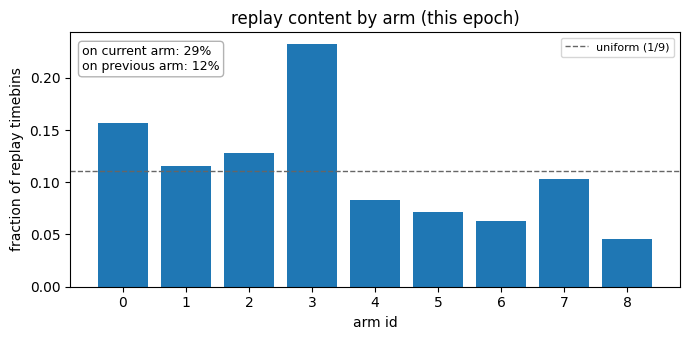

In [12]:
arm_mass = event_arm_table.groupby("arm")["arm_count_hard"].sum()
arm_mass = arm_mass / arm_mass.sum()
frac_current = (
    (event_arm_table["arm_count_hard"] * event_arm_table["is_current"]).sum()
    / event_arm_table["arm_count_hard"].sum()
)
frac_prev = (
    (event_arm_table["arm_count_hard"] * event_arm_table["is_prev"]).sum()
    / event_arm_table["arm_count_hard"].sum()
)

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.bar(arm_mass.index, arm_mass.values, color="C0")
ax.axhline(1 / 9, color="0.4", ls="--", lw=1, label="uniform (1/9)")
ax.set(xlabel="arm id", ylabel="fraction of replay timebins",
       title="replay content by arm (this epoch)")
ax.set_xticks(range(9))
ax.legend(fontsize=8)
ax.text(0.02, 0.95,
        f"on current arm: {frac_current:.0%}\non previous arm: {frac_prev:.0%}",
        transform=ax.transAxes, va="top", fontsize=9,
        bbox=dict(boxstyle="round", fc="white", ec="0.7"))
fig.tight_layout()

## 6. Regression models (this epoch = one production unit)

All four families are fit on **this single session's** events/stops, exactly
as the production per-session loop does. Each family conditions on a
within-session unit (event or stop), so no event-level constant is
identifiable — there is no intercept in the conditional models.

We keep a small presentation helper that only *extracts* fields already
returned by the fitters (AIC/BIC/log-likelihood/pseudo-R²/coefficients).
Nothing statistical is computed here.

In [13]:
def fits_to_stat_frame(fits: dict[str, dict | None], spec_map: dict) -> pd.DataFrame:
    """Tidy per-model fit statistics from fitter return dicts (presentation only).

    The four fitters return slightly different key sets — the conditional
    Poisson emits ``aic``/``pseudo_r2``; the rate GLM emits ``aic`` and
    ``n_stops``; the conditional logit emits only the partial ``llf`` (no
    AIC). We surface a common unit count (``n_units`` = events or stops) and
    only compute ``delta_aic`` over the models that actually report an AIC.
    """
    rows = []
    for name, res in fits.items():
        spec = spec_map[name]
        if res is None:
            rows.append({"model": name, "status": "skipped (insufficient data)",
                         "n_predictors": len(spec.predictors)})
            continue
        rows.append({
            "model": name,
            "n_predictors": len(spec.predictors),
            "n_units": res.get("n_events", res.get("n_stops")),
            "llf": res.get("llf"),
            "aic": res.get("aic"),
            "bic": res.get("bic"),
            "pseudo_r2": res.get("pseudo_r2"),
            "status": "fit",
        })
    out = pd.DataFrame(rows).set_index("model")
    # Drop columns a given family never populates (e.g. no AIC for the logit).
    out = out.dropna(axis=1, how="all")
    if "aic" in out:
        out["delta_aic"] = out["aic"] - out["aic"].min()
    return out


def coefs_to_frame(res: dict, spec) -> pd.DataFrame:
    """Coefficient / SE / p-value table for one fitted model."""
    rows = []
    for p in spec.predictors:
        rows.append({
            "predictor": p,
            "coef": res.get(f"coef_{p}"),
            "se": res.get(f"bse_{p}"),
            "pval": res.get(f"pval_{p}"),
            "vif": res.get(f"vif_{p}"),
        })
    return pd.DataFrame(rows).set_index("predictor")

### 6a. Arm content — M0–M7 (conditional Poisson)

Response `arm_count_hard`, grouped by `event_id`, 9 arms per event. M0 is the
uniform null; M0a adds arm geometry; M1–M7 add spatial context, value/memory,
and SWR interactions in nested steps. Lower AIC = better.

In [14]:
arm_fits = {
    name: fit_conditional_poisson(
        event_arm_table,
        predictors=list(spec.predictors),
        response_col="arm_count_hard",
        event_col="event_id",
        n_categories=9,
    )
    for name, spec in MODEL_HIERARCHY.items()
}
arm_stats = fits_to_stat_frame(arm_fits, MODEL_HIERARCHY)
arm_stats

,n_predictors,n_units,llf,aic,bic,pseudo_r2,status,delta_aic
model,,,,,,,,
M0,0,1714,-144601.546659,289203.093318,289203.093318,0.000000,fit,50808.066331
M0a,8,1714,-137462.897618,274941.795237,274985.367918,0.049368,fit,36546.768250
M1,9,1714,-132836.196437,265690.392875,265739.412140,0.081364,fit,27295.365887
M2,10,1714,-132477.308300,264974.616600,265029.082451,0.083846,fit,26579.589613
M3,11,1622,-124905.581243,249833.162486,249892.468053,0.090201,fit,11438.135499
M4,12,1622,-124817.886397,249659.772793,249724.469776,0.090840,fit,11264.745806
M5,13,1622,-124780.946078,249587.892156,249657.980554,0.091109,fit,11192.865169
M6,15,1622,-122874.809795,245779.619591,245860.490819,0.104993,fit,7384.592604
M7,18,1622,-119179.513494,238395.026987,238492.072461,0.131909,fit,0.000000


Coefficients of the full model (M7). Positive `is_current` = replay biased
toward the arm the animal is currently on; `swr_x_*` terms = how SWR-overlap
events differ. `vif` flags any predictor that became near-collinear within
this one session.

In [15]:
if arm_fits["M7"] is not None:
    m7_coefs = coefs_to_frame(arm_fits["M7"], MODEL_HIERARCHY["M7"])
    display(m7_coefs.round(3))  # noqa: F821 (IPython display)
else:
    print("M7 did not fit on this epoch (insufficient/again collinear data).")

,coef,se,pval,vif
predictor,,,,
arm_fe_0,0.854,0.024,0.0,2.338
arm_fe_1,0.935,0.025,0.0,2.475
arm_fe_2,0.839,0.025,0.0,2.394
arm_fe_3,1.552,0.026,0.0,3.295
arm_fe_4,0.425,0.024,0.0,1.847
arm_fe_5,0.426,0.026,0.0,2.400
arm_fe_6,0.341,0.024,0.0,1.778
arm_fe_7,0.807,0.022,0.0,1.778
is_current,0.996,0.017,0.0,2.438


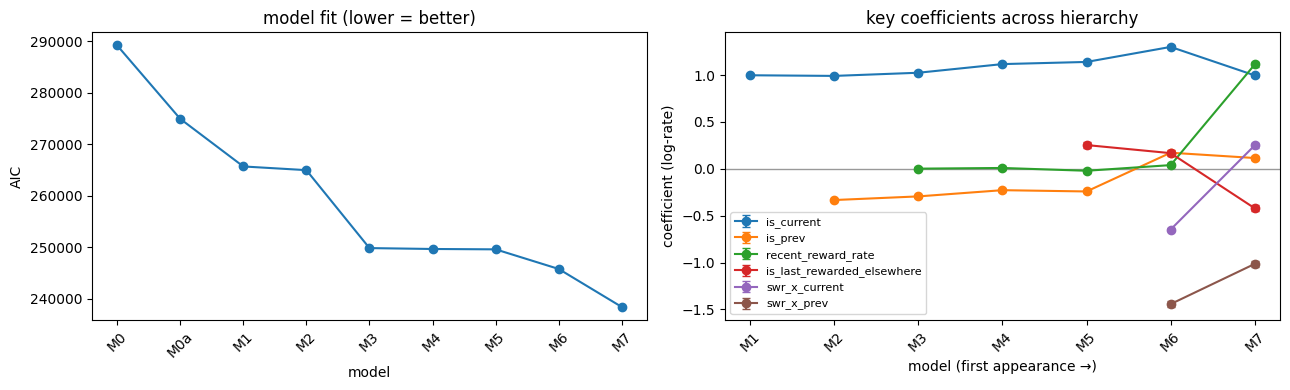

In [16]:
# AIC trajectory + key non-geometry coefficients across the hierarchy.
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

fit_models = arm_stats[arm_stats["status"] == "fit"]
axes[0].plot(fit_models.index, fit_models["aic"], "o-", color="C0")
axes[0].set(xlabel="model", ylabel="AIC", title="model fit (lower = better)")
axes[0].tick_params(axis="x", rotation=45)

# Track a few interpretable coefficients where present.
track = ["is_current", "is_prev", "recent_reward_rate",
         "is_last_rewarded_elsewhere", "swr_x_current", "swr_x_prev"]
for predictor in track:
    xs, ys, es = [], [], []
    for name, res in arm_fits.items():
        if res is not None and f"coef_{predictor}" in res:
            xs.append(name)
            ys.append(res[f"coef_{predictor}"])
            es.append(res.get(f"bse_{predictor}", np.nan))
    if xs:
        axes[1].errorbar(xs, ys, yerr=es, marker="o", capsize=3, label=predictor)
axes[1].axhline(0, color="0.6", lw=1)
axes[1].set(xlabel="model (first appearance →)", ylabel="coefficient (log-rate)",
            title="key coefficients across hierarchy")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend(fontsize=8)
fig.tight_layout()

### 6b. Patch content — P0–P4 (conditional Poisson, 3 categories)

Same estimator, arms collapsed to the three patches. Requires ≥10 events per
session (`fit_conditional_poisson` rejects below `2 × n_predictors` events;
patch fits also gate at 10 in production).

In [17]:
patch_fits = {
    name: fit_conditional_poisson(
        event_patch_table,
        predictors=list(spec.predictors),
        response_col="patch_count_hard",
        event_col="event_id",
        n_categories=3,
    )
    for name, spec in MODEL_PATCH.items()
}
patch_stats = fits_to_stat_frame(patch_fits, MODEL_PATCH)
patch_stats

,n_predictors,n_units,llf,aic,bic,pseudo_r2,status,delta_aic
model,,,,,,,,
P0,0,1714,-72300.773330,144601.546659,144601.546659,0.000000,fit,6033.336916
P1,1,1714,-70489.349267,140980.698534,140986.145119,0.025054,fit,2412.488791
P2,2,1714,-70466.367779,140936.735557,140947.628728,0.025372,fit,2368.525815
P3,3,1697,-69481.908117,138969.816234,138986.126085,0.028432,fit,401.606491
P4,5,1697,-69279.104871,138568.209743,138595.392829,0.031268,fit,0.000000


In [18]:
if patch_fits["P4"] is not None:
    display(coefs_to_frame(patch_fits["P4"], MODEL_PATCH["P4"]).round(3))  # noqa: F821
else:
    print("P4 did not fit on this epoch.")

,coef,se,pval,vif
predictor,,,,
is_current_patch,0.454,0.014,0.000,2.476
is_last_rewarded_patch_elsewhere,-0.452,0.069,0.000,1.067
cumulative_reward_patch,0.049,0.003,0.000,2.305
swr_x_current_patch,-0.312,0.016,0.000,1.619
swr_x_last_rewarded_patch_elsewhere,-14.613,274.168,0.957,1.041


### 6c. Event rate — R0–R3 (Poisson GLM, log-time offset)

`fit_rate_model` regresses `n_events` per stop with a `log(immobility_time)`
offset (so the coefficient is on *rate*, not raw count). Unit = stop;
production gate is ≥20 stops per session.

In [19]:
rate_fits = {
    name: fit_rate_model(
        stop_table,
        predictors=list(spec.predictors),
        response_col="n_events",
        offset_col="immobility_time",
        min_stops=20,
    )
    for name, spec in MODEL_RATE.items()
}
rate_stats = fits_to_stat_frame(rate_fits, MODEL_RATE)
rate_stats

,n_predictors,n_units,llf,aic,bic,status,delta_aic
model,,,,,,,
R0,0,2238,-1541.534148,3085.068295,3090.781633,fit,198.704161
R1,2,2238,-1524.656322,3055.312645,3072.452659,fit,168.948511
R2,3,2227,-1505.322468,3018.644935,3041.478578,fit,132.280801
R3,4,2227,-1438.182067,2886.364134,2914.906188,fit,0.000000


In [20]:
if rate_fits["R3"] is not None:
    display(coefs_to_frame(rate_fits["R3"], MODEL_RATE["R3"]).round(3))  # noqa: F821
else:
    print("R3 did not fit on this epoch (need >=20 stops).")

,coef,se,pval,vif
predictor,,,,
is_after_omission,0.053,0.074,0.469,None
is_after_switch,0.088,0.097,0.365,None
recent_trial_reward_rate,-0.445,0.144,0.002,None
is_swr_stop,0.770,0.069,0.000,None


### 6d. Next-arm choice — C_* (conditional logit)

Does replay content predict where the animal *goes next*, beyond a
behavioural baseline? `build_choice_dataset` makes a stop × candidate-arm
table (well arms minus the current arm); `fit_choice_model` fits a
conditional logit grouped by stop. `C_full` vs `C_behavior` is the primary
test (does `replay_frac` add predictive power).

In [21]:
choice_df = build_choice_dataset(event_table, event_arm_table, stop_table)
print("choice_df:", choice_df.shape,
      f"({choice_df['stop_id'].nunique()} stops × candidate arms)")

choice_fits = {}
for name, spec in MODEL_CHOICE.items():
    preds = [p for p in spec.predictors if p in choice_df.columns]
    choice_fits[name] = fit_choice_model(choice_df, preds, stop_col="stop_id")
choice_stats = fits_to_stat_frame(choice_fits, MODEL_CHOICE)
choice_stats

choice_df: (1940, 20) (388 stops × candidate arms)


,n_predictors,n_units,llf,status
model,,,,
C_replay_only,1,388,-623.169317,fit
C_behavior,3,361,-344.098652,fit
C_full,4,361,-343.884731,fit
C_full_swr_split,5,171,-127.491679,fit


Primary choice test: does adding replay content (`C_full`) improve on the
behavioural baseline (`C_behavior`)? The conditional logit reports a partial
log-likelihood, so we read the gain directly (1 added predictor,
`replay_frac`). A small gain = replay adds little to next-arm prediction
beyond behaviour — consistent with the population finding.

In [22]:
if choice_fits["C_full"] and choice_fits["C_behavior"]:
    d_llf = choice_fits["C_full"]["llf"] - choice_fits["C_behavior"]["llf"]
    print(f"C_behavior partial llf : {choice_fits['C_behavior']['llf']:.2f}")
    print(f"C_full     partial llf : {choice_fits['C_full']['llf']:.2f}")
    print(f"gain from +replay_frac : {d_llf:.2f}  (1 df)")
    print(f"replay_frac coef       : {choice_fits['C_full']['coef_replay_frac']:.3f}"
          f"  (p = {choice_fits['C_full']['pval_replay_frac']:.3g})")
else:
    print("C_full / C_behavior did not both fit on this epoch.")

C_behavior partial llf : -344.10
C_full     partial llf : -343.88
gain from +replay_frac : 0.21  (1 df)
replay_frac coef       : 0.200  (p = 0.507)


In [23]:
if choice_fits["C_full"] is not None:
    display(coefs_to_frame(choice_fits["C_full"], MODEL_CHOICE["C_full"]).round(3))  # noqa: F821
else:
    print("C_full did not fit on this epoch (need enough valid-next-arm stops).")

,coef,se,pval,vif
predictor,,,,
visit_recency,-0.088,0.013,0.000,None
cumulative_reward,0.441,0.097,0.000,None
recent_reward_rate,-0.622,0.295,0.035,None
replay_frac,0.200,0.301,0.507,None


## 7. Summary

| Family | Estimator | Unit | Asks |
|---|---|---|---|
| **M0–M7** | conditional Poisson (9 arms) | event | *Which arm* does replay represent? |
| **P0–P4** | conditional Poisson (3 patches) | event | *Which patch* does replay represent? |
| **R0–R3** | Poisson GLM + log-time offset | stop | *How often* do events occur? |
| **C_\*** | conditional logit | stop | Does replay predict the *next choice*? |

What this one epoch shows is summarized in the AIC tables above: each added
block either lowers AIC (earns its parameters) or does not. The robust,
replicated population effects (current-arm bias; SWR broadening off the
current/previous arm; suppression by cumulative reward) are *aggregates* of
many such per-session fits.

**Caveat — single-session estimates are noisy.** With one epoch's events,
coefficients have wide standard errors and some models may skip on
insufficient data. The population pipeline
(`scripts/content/fit_replay_content_models.py` →
`model_comparison.run_full_hierarchy_comparison`) fits this exact per-session
table across all ~200 sessions and tests effects with Wilcoxon + multiple-
comparison control. Per the project's own record, several effects that look
suggestive in a single session do **not** survive autocorrelation /
multiple-comparison correction — so read this notebook as *one unit of* the
analysis, not as the result.